# Long Short-Term Memory (LSTM) Networks

## What is an LSTM?
Long Short-Term Memory (LSTM) is an advanced architecture of **Recurrent Neural Networks (RNN)**. It was specifically designed to learn long-term dependencies in sequence data, overcoming the major limitations of traditional RNNs.

## Why use LSTMs? (The Problem it Solves)
When processing long sequences of data, standard RNNs suffer from the **Vanishing and Exploding Gradient Problem**. Because they repeatedly multiply the same weight matrices across many time steps during backpropagation, the gradients either shrink towards zero (the network "forgets" earlier inputs and stops learning) or grow infinitely large (the network becomes unstable). 

LSTMs solve this by introducing an internal mechanism called **gates** that can regulate the flow of information, deciding exactly what to keep, what to update, and what to throw away.

---

## Architecture & Mathematical Intuition

The core intuition behind LSTMs is the separation of memory into two distinct paths:
1. **Cell State ($C_t$)**: The long-term memory. It acts like a conveyer belt or highway running straight down the entire chain, with only minor linear interactions. It's very easy for information to flow along it unchanged.
2. **Hidden State ($h_t$)**: The short-term memory (and the actual output of the LSTM cell at time $t$).

LSTMs control the Cell State using three primary "gates." These gates use the **Sigmoid ($\sigma$)** activation function (outputs $0$ to $1$, where $0$ means "let nothing through" and $1$ means "let everything through") and the **Tanh** function (outputs $-1$ to $1$ to normalize values).

### 1. Forget Gate
Decides what information from the long-term memory should be thrown away or kept. It looks at the previous hidden state and current input.
$$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$

### 2. Input Gate
Decides what new information is going to be stored in the long-term memory. It has two parts:
* A sigmoid layer decides which values we will update: 
  $$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
* A tanh layer creates a vector of new candidate values: 
  $$\tilde{C}_t = \tanh(W_c \cdot [h_{t-1}, x_t] + b_c)$$

### 3. Cell State Update
We then update the old cell state ($C_{t-1}$) into the new cell state ($C_t$) by multiplying the old state by the forget gate, and adding the new scaled candidate values.
$$C_t = f_t \cdot C_{t-1} + i_t \cdot \tilde{C}_t$$

### 4. Output Gate
Decides what the next hidden state (short-term memory) should be. The hidden state is a filtered version of our new cell state.
$$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$
$$h_t = o_t \cdot \tanh(C_t)$$

---

## Common Applications
Due to their ability to process sequences and remember past contexts, LSTMs are widely used in:
* **Time Series Forecasting:** Predicting stock prices, weather, or energy demand.
* **Natural Language Processing (NLP):** Text classification, sentiment analysis, and historically, machine translation (though mostly superseded by Transformers like GPT/BERT for large-scale tasks).
* **Speech Recognition:** Converting speech to text, as speech is inherently a sequence of audio signals over time.
* **Anomaly Detection:** Monitoring server logs, ECG data, or network traffic for unusual sequences of events.

---

In [15]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import torch_directml

In [16]:
NUM_DATA_POINTS = 1000
NUM_EPOCHS = 100
LEARNING_RATE = 0.01
# DEVICE = torch_directml.device(0)     torch_directml is not available as it doesn't support all the operations in recurrent layers
DEVICE = torch.device('cpu')

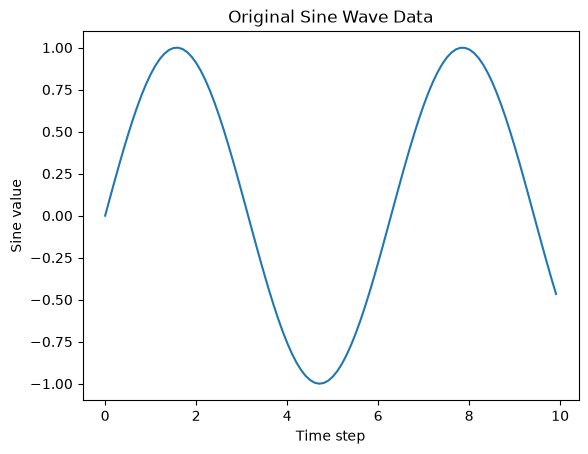

In [17]:
x_values = np.linspace(0, 100, NUM_DATA_POINTS)

# Calculate the sine of each x value to create our time series data
y_values = np.sin(x_values)

# Plot the first 100 points to visualize the generated sine wave
plt.plot(x_values[:100], y_values[:100])
plt.title("Original Sine Wave Data")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.show()

In [18]:
# Function to create sequences (features) and corresponding labels (targets)
def create_sequences(data, sequence_length):
    inputs = []
    targets = []
    
    # Iterate through the data to create sliding windows
    for i in range(len(data) - sequence_length):
        # Extract a window of 'sequence_length' points
        window = data[i:(i + sequence_length)]
        # The target is the immediate next point after the window
        target = data[i + sequence_length]
        
        inputs.append(window)
        targets.append(target)
        
    return np.array(inputs), np.array(targets)

# Set the sequence length (how many past steps the model looks at)
seq_length = 20

# Generate the formatted inputs (X) and targets (y)
X_data, y_target = create_sequences(y_values, seq_length)

# Convert numpy arrays to PyTorch tensors and cast to 32-bit floating point
X_tensor = torch.tensor(X_data, dtype=torch.float32, device=DEVICE)
y_tensor = torch.tensor(y_target, dtype=torch.float32, device=DEVICE)

# Reshape tensors to match PyTorch LSTM expectations: [batch_size, sequence_length, num_features]
# unsqueeze(-1) adds a new dimension at the last position (index -1)
X_tensor = X_tensor.unsqueeze(-1)
y_tensor = y_tensor.unsqueeze(-1)

print(f"Shape of input tensor (X_tensor): {X_tensor.shape}") 
# Expected: torch.Size([980, 20, 1])
print(f"Shape of target tensor (y_tensor): {y_tensor.shape}") 
# Expected: torch.Size([980, 1])

Shape of input tensor (X_tensor): torch.Size([980, 20, 1])
Shape of target tensor (y_tensor): torch.Size([980, 1])


In [19]:
class SineLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=50, output_size=1):
        super(SineLSTM, self).__init__()
        
        # Store the hidden size for later reference if needed
        self.hidden_size = hidden_size
        
        # Define the LSTM layer
        # batch_first=True tells the model to expect input tensors of shape (batch, seq, feature)
        self.lstm = nn.LSTM(input_size=input_size, 
                            hidden_size=hidden_size, 
                            batch_first=True)
        
        # Define the fully connected (linear) layer to map LSTM output to our single numeric prediction
        self.linear = nn.Linear(in_features=hidden_size, out_features=output_size)

    def forward(self, x):
        # Pass input sequence through the LSTM layer
        # lstm_out contains all hidden states across all time steps
        # We ignore the returned final hidden state and cell state tuples (_)
        lstm_out, _ = self.lstm(x)
        
        # Extract the hidden state from the very last time step of the sequence
        # Syntax means: [all_batches, last_time_step, all_hidden_features]
        last_time_step_out = lstm_out[:, -1, :]
        
        # Map the final hidden state to a single output value
        prediction = self.linear(last_time_step_out)
        
        return prediction

# Instantiate the model
model = SineLSTM().to(DEVICE)
print(model)

SineLSTM(
  (lstm): LSTM(1, 50, batch_first=True)
  (linear): Linear(in_features=50, out_features=1, bias=True)
)


In [20]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [21]:
for epoch in range(NUM_EPOCHS):
    predictions = model(X_tensor)
    loss = criterion(predictions, y_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 20 == 0:
        print(f'Epoch [{epoch+1}/{NUM_EPOCHS}], Loss: {loss.item():.6f}')

Epoch [20/100], Loss: 0.001511
Epoch [40/100], Loss: 0.000430
Epoch [60/100], Loss: 0.000112
Epoch [80/100], Loss: 0.000016
Epoch [100/100], Loss: 0.000006


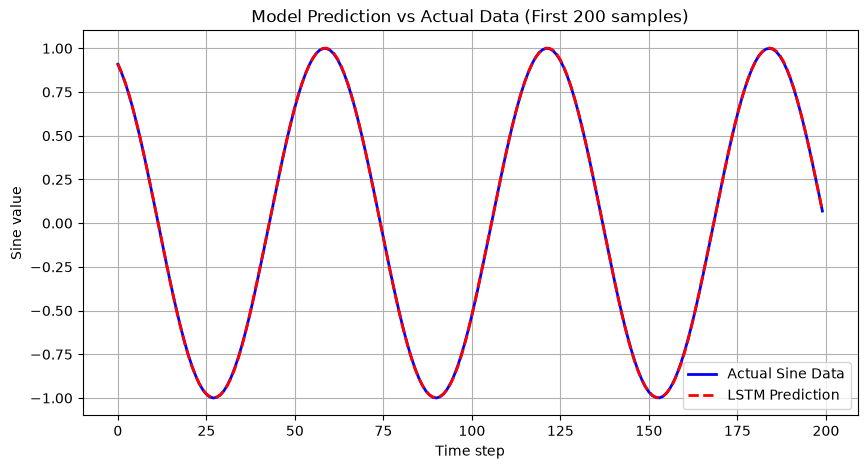

In [22]:
model.eval()

with torch.no_grad():
    predicted_tensor = model(X_tensor)
    
    predicted_numpy = predicted_tensor.cpu().numpy().squeeze()
    actual_numpy = y_tensor.cpu().numpy().squeeze()

plt.figure(figsize=(10, 5))
plt.plot(actual_numpy[:200], label='Actual Sine Data', color='blue', linewidth=2)
plt.plot(predicted_numpy[:200], label='LSTM Prediction', color='red', linestyle='--', linewidth=2)
plt.title("Model Prediction vs Actual Data (First 200 samples)")
plt.xlabel("Time step")
plt.ylabel("Sine value")
plt.legend()
plt.grid(True)
plt.show()